# 02 - Detecção de crateras

Comparamos dois detectores clássicos (`pouso_lunar/detector.py`).

**Hough**: tons de cinza → CLAHE → blur gaussiano → `HoughCircles` → supressão de sobrepostos, com validação opcional por contraste.

**Sombra-brilho:**
1. Blur gaussiano.
2. **Limiar local**: é sombra o pixel bem mais escuro que a média da vizinhança, e brilho o bem mais claro.
3. **Abertura morfológica**.
4. **Componentes conectados e centroides**.
5. **Pareamento** de cada sombra com o brilho vizinho na direção do sol.

**Por que o segundo método existe:** com o sol baixo, as crateras pequenas (2 a 4 km, ou 10 a 20 px) não aparecem como um contorno circular fechado. Elas aparecem como uma mancha escura (a parede em sombra) colada a uma mancha clara (a parede iluminada). Isso foi visto no diagnóstico mais abaixo.

**Protocolo:**
1. A escolha de parâmetros usa **só a metade de ajuste** (oeste).
2. A melhor configuração (maior F1) é avaliada **uma única vez** na metade de teste (leste).
3. Critério de acerto: centro a menos de 0,5·r do centro do gabarito e razão de raios entre 0,5 e 2, com casamento um-para-um.

In [1]:
import sys
sys.path.insert(0, "..")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pouso_lunar import config
from pouso_lunar.dados import carregar_gabarito, carregar_mapa, metade
from pouso_lunar.detector import ParamsDeteccao, detectar_crateras
from pouso_lunar.metricas import casar_deteccoes, por_faixa, prf1

config.PASTA_RESULTADOS.mkdir(exist_ok=True)
mapa, info = carregar_mapa()
gab = carregar_gabarito(info)[["x", "y", "r_px"]].to_numpy()
gab_aj, gab_te = metade(gab, info, "ajuste"), metade(gab, info, "teste")
print(f"gabarito (2 a 24 km): {len(gab_aj)} crateras no ajuste, {len(gab_te)} no teste")
R_MIN, R_MAX = config.DIAM_MIN_PX // 2, config.DIAM_MAX_PX // 2


def avaliar(p: ParamsDeteccao, qual="ajuste"):
    t0 = time.perf_counter()
    det = detectar_crateras(mapa, p)
    dt = time.perf_counter() - t0
    d, g = metade(det, info, qual), (gab_aj if qual == "ajuste" else gab_te)
    m = casar_deteccoes(d, g)
    pr, rc, f1 = prf1(m["tp"], m["fp"], m["fn"])
    return {"n_det": len(d), "tp": m["tp"], "fp": m["fp"], "fn": m["fn"],
            "precisao": pr, "recall": rc, "f1": f1, "tempo_s": dt}, det

gabarito (2 a 24 km): 739 crateras no ajuste, 562 no teste


## Ablação 1: Hough (metade de ajuste)

Quatro configurações, cada uma acrescentando uma etapa. Em cada uma varremos o limiar do acumulador (`param2`): limiares menores aceitam círculos com menos votos, o que traz mais recall e mais falsos positivos.

In [2]:
configs_hough = {
    "Hough (a) sem pré-proc.": dict(usar_clahe=False, blur_ksize=0),
    "Hough (b) só blur": dict(usar_clahe=False, blur_ksize=5),
    "Hough (c) CLAHE + blur": dict(usar_clahe=True, blur_ksize=5),
    "Hough (d) CLAHE + blur + contraste": dict(usar_clahe=True, blur_ksize=5, validar_contraste=True),
}
linhas = []
for nome, kw in configs_hough.items():
    for acc in [20, 30, 40, 60]:
        p = ParamsDeteccao(metodo="hough", r_min=R_MIN, r_max=R_MAX, acumulador=acc, **kw)
        res, _ = avaliar(p)
        linhas.append({"config": nome, "variavel": acc, "params": json.dumps({"metodo": "hough", "acumulador": acc, **kw}), **res})
        print(f"{nome:36s} acc={acc:2d}  P={res['precisao']:.3f} R={res['recall']:.3f} F1={res['f1']:.3f}  ({res['tempo_s']:.1f}s)")

Hough (a) sem pré-proc.              acc=20  P=0.028 R=0.399 F1=0.052  (3.4s)


Hough (a) sem pré-proc.              acc=30  P=0.030 R=0.168 F1=0.050  (1.4s)


Hough (a) sem pré-proc.              acc=40  P=0.035 R=0.069 F1=0.047  (0.5s)
Hough (a) sem pré-proc.              acc=60  P=0.125 R=0.005 F1=0.010  (0.1s)


Hough (b) só blur                    acc=20  P=0.097 R=0.191 F1=0.128  (0.3s)
Hough (b) só blur                    acc=30  P=0.298 R=0.053 F1=0.090  (0.1s)
Hough (b) só blur                    acc=40  P=0.867 R=0.018 F1=0.034  (0.1s)


Hough (b) só blur                    acc=60  P=0.000 R=0.000 F1=0.000  (0.1s)


Hough (c) CLAHE + blur               acc=20  P=0.020 R=0.390 F1=0.037  (7.1s)


... (2 outputs left out)

Hough (d) CLAHE + blur + contraste   acc=20  P=0.028 R=0.273 F1=0.050  (307.3s)


Hough (d) CLAHE + blur + contraste   acc=30  P=0.029 R=0.129 F1=0.047  (135.5s)


Hough (d) CLAHE + blur + contraste   acc=40  P=0.033 R=0.060 F1=0.043  (56.0s)


Hough (d) CLAHE + blur + contraste   acc=60  P=0.130 R=0.004 F1=0.008  (1.6s)


## Ablação 2: sombra-brilho (metade de ajuste)

Variamos o limiar local (quanto mais escuro ou mais claro que a vizinhança o pixel precisa ser), a janela da média local e o uso do CLAHE. A última configuração tira as restrições de pareamento (alcance curto e áreas parecidas) para medir o efeito delas.

In [3]:
LIMIARES = [12, 15, 18, 21, 24]
configs_sombra = {
    "Sombra sem CLAHE, janela 15": (dict(usar_clahe=False, janela_media=15), LIMIARES),
    "Sombra sem CLAHE, janela 21": (dict(usar_clahe=False, janela_media=21), LIMIARES),
    "Sombra sem CLAHE, janela 31": (dict(usar_clahe=False, janela_media=31), LIMIARES),
    # o CLAHE estica o contraste, então o limiar ótimo é bem mais alto: grade maior
    "Sombra com CLAHE, janela 21": (dict(usar_clahe=True, janela_media=21), [18, 24, 30, 36, 42, 48]),
    "Sombra sem restrições de par": (dict(usar_clahe=False, janela_media=21, alcance_fator=4.0, razao_area_max=1e9), LIMIARES),
}
for nome, (kw, limiares) in configs_sombra.items():
    for lim in limiares:
        p = ParamsDeteccao(metodo="sombra", r_min=R_MIN, r_max=R_MAX, limiar_sombra=lim,
                           direcao_sol_graus=config.DIRECAO_SOL_GRAUS, **kw)
        res, _ = avaliar(p)
        linhas.append({"config": nome, "variavel": lim, "params": json.dumps({"metodo": "sombra", "limiar_sombra": lim, **kw}), **res})
        print(f"{nome:36s} lim={lim:2d}  P={res['precisao']:.3f} R={res['recall']:.3f} F1={res['f1']:.3f}  ({res['tempo_s']:.1f}s)")
ablacao = pd.DataFrame(linhas)
ablacao.to_csv(config.PASTA_RESULTADOS / "deteccao_ablacao.csv", index=False)

Sombra sem CLAHE, janela 15          lim=12  P=0.333 R=0.392 F1=0.360  (1.0s)


Sombra sem CLAHE, janela 15          lim=15  P=0.491 R=0.349 F1=0.408  (0.6s)


Sombra sem CLAHE, janela 15          lim=18  P=0.627 R=0.284 F1=0.391  (0.3s)


Sombra sem CLAHE, janela 15          lim=21  P=0.710 R=0.222 F1=0.338  (0.3s)
Sombra sem CLAHE, janela 15          lim=24  P=0.756 R=0.164 F1=0.269  (0.2s)


Sombra sem CLAHE, janela 21          lim=12  P=0.296 R=0.405 F1=0.342  (1.0s)


Sombra sem CLAHE, janela 21          lim=15  P=0.438 R=0.398 F1=0.417  (0.6s)


... (15 outputs left out)

Sombra sem restrições de par         lim=15  P=0.324 R=0.426 F1=0.368  (0.6s)


Sombra sem restrições de par         lim=18  P=0.426 R=0.384 F1=0.404  (0.4s)


Sombra sem restrições de par         lim=21  P=0.541 R=0.325 F1=0.406  (0.3s)


Sombra sem restrições de par         lim=24  P=0.617 R=0.257 F1=0.363  (0.2s)


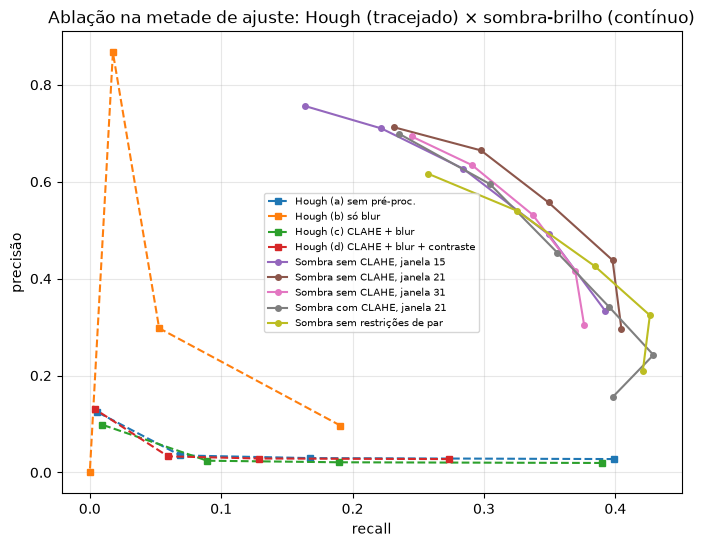

,config,variavel,precisao,recall,f1,tempo_s
0,Hough (a) sem pré-proc.,20,0.028,0.399,0.052,3.429
4,Hough (b) só blur,20,0.097,0.191,0.128,0.251
10,Hough (c) CLAHE + blur,40,0.024,0.089,0.038,1.219
12,Hough (d) CLAHE + blur + contraste,20,0.028,0.273,0.050,307.267
17,"Sombra sem CLAHE, janela 15",15,0.491,0.349,0.408,0.557
23,"Sombra sem CLAHE, janela 21",18,0.557,0.349,0.429,0.394
28,"Sombra sem CLAHE, janela 31",18,0.532,0.337,0.413,0.386
35,"Sombra com CLAHE, janela 21",42,0.595,0.304,0.403,0.303
40,Sombra sem restrições de par,21,0.541,0.325,0.406,0.267


In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
for nome, g in ablacao.groupby("config", sort=False):
    estilo = "s--" if nome.startswith("Hough") else "o-"
    ax.plot(g["recall"], g["precisao"], estilo, label=nome, ms=4)
ax.set_xlabel("recall"); ax.set_ylabel("precisão")
ax.set_title("Ablação na metade de ajuste: Hough (tracejado) × sombra-brilho (contínuo)")
ax.grid(alpha=0.3); ax.legend(fontsize=7)
fig.savefig(config.PASTA_RESULTADOS / "deteccao_ablacao.png", dpi=110, bbox_inches="tight")
plt.show()
ablacao.loc[ablacao.groupby("config", sort=False)["f1"].idxmax(), ["config", "variavel", "precisao", "recall", "f1", "tempo_s"]].round(3)

## Escolha dos parâmetros

A configuração escolhida é a de **maior F1 no ajuste**. Os valores vão para `config.PARAMS_DETECCAO`, usado pela demo.

In [5]:
melhor = ablacao.loc[ablacao["f1"].idxmax()]
escolha = {"r_min": R_MIN, "r_max": R_MAX, **json.loads(melhor.params)}
# efeito das restrições de pareamento no MESMO limiar
mesmo = ablacao[(ablacao.variavel == melhor.variavel) & ablacao.config.isin(["Sombra sem restrições de par", melhor.config])]
print(mesmo[["config", "variavel", "precisao", "recall", "f1"]].round(3).to_string(index=False))
print("melhor no ajuste:", melhor.config, "| variável", melhor.variavel, f"| F1 = {melhor.f1:.3f}")
print("PARAMS_DETECCAO =", escolha)
(config.PASTA_RESULTADOS / "deteccao_params.json").write_text(json.dumps(escolha, indent=2))
melhor_hough = ablacao[ablacao.config.str.startswith("Hough")].sort_values("f1").iloc[-1]
escolha_hough = {"r_min": R_MIN, "r_max": R_MAX, **json.loads(melhor_hough.params)}

                      config  variavel  precisao  recall    f1
 Sombra sem CLAHE, janela 21        18     0.557   0.349 0.429
Sombra sem restrições de par        18     0.426   0.384 0.404
melhor no ajuste: Sombra sem CLAHE, janela 21 | variável 18 | F1 = 0.429
PARAMS_DETECCAO = {'r_min': 5, 'r_max': 60, 'metodo': 'sombra', 'limiar_sombra': 18, 'usar_clahe': False, 'janela_media': 21}


## Resultado na metade de teste

Estes são os números que valem: a metade de teste não foi usada para escolher nada. Para comparar, o melhor Hough também é avaliado no teste.

In [6]:
res_te, det = avaliar(ParamsDeteccao(direcao_sol_graus=config.DIRECAO_SOL_GRAUS, **escolha), "teste")
res_te_h, _ = avaliar(ParamsDeteccao(**escolha_hough), "teste")
det_te = metade(det, info, "teste")
faixas = por_faixa(det_te, gab_te)
cols = ("tp", "fp", "fn", "precisao", "recall", "f1")
tabela = pd.concat([
    pd.DataFrame([{"faixa": "global", **{k: res_te[k] for k in cols}}]),
    faixas,
    pd.DataFrame([{"faixa": "global (melhor Hough)", **{k: res_te_h[k] for k in cols}}]),
], ignore_index=True)
tabela.to_csv(config.PASTA_RESULTADOS / "deteccao_metricas.csv", index=False)
print(f"tempo de detecção no mapa inteiro ({mapa.shape[1]}x{mapa.shape[0]} px): {res_te['tempo_s']:.2f} s")
tabela.round(3)

tempo de detecção no mapa inteiro (3033x3033 px): 0.37 s


,faixa,tp,fp,fn,precisao,recall,f1
0,global,218,141,344,0.607,0.388,0.473
1,10-20,162,97,284,0.625,0.363,0.460
2,20-40,52,42,37,0.553,0.584,0.568
3,>40,4,2,23,0.667,0.148,0.242
4,global (melhor Hough),114,1167,448,0.089,0.203,0.124


## Onde o detector acerta e erra

Dois tiles da metade de teste, um de mar e um de terras altas. **Verde:** acerto (TP). **Vermelho:** falso positivo. **Amarelo:** cratera do gabarito não encontrada (FN).

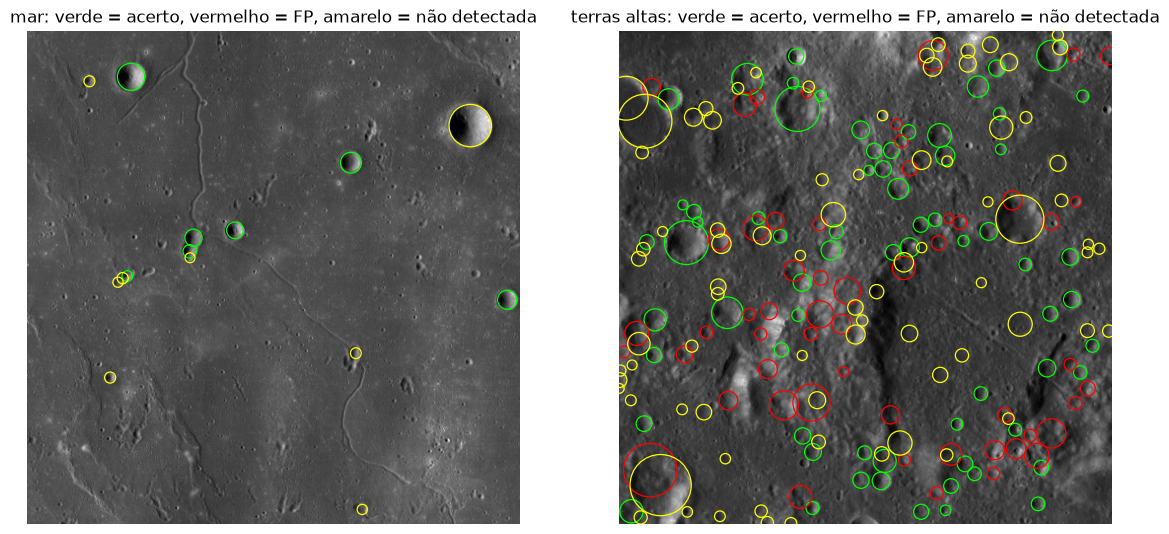

In [7]:
m = casar_deteccoes(det_te, gab_te)
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, (x0, y0, titulo) in zip(axs, [(int(info.largura * 0.55), int(info.altura * 0.62), "mar"),
                                      (int(info.largura * 0.80), int(info.altura * 0.78), "terras altas")]):
    L = 500
    def no_tile(c):
        return (c[:, 0] >= x0) & (c[:, 0] < x0 + L) & (c[:, 1] >= y0) & (c[:, 1] < y0 + L)
    ax.imshow(mapa[y0:y0 + L, x0:x0 + L], cmap="gray")
    for c, cor in ((det_te[m["mascara_det_tp"] & no_tile(det_te)], "lime"),
                   (det_te[~m["mascara_det_tp"] & no_tile(det_te)], "red"),
                   (gab_te[~m["mascara_gab_tp"] & no_tile(gab_te)], "yellow")):
        for x, y, r in c:
            ax.add_patch(plt.Circle((x - x0, y - y0), r, fill=False, color=cor, lw=0.9))
    ax.set_title(f"{titulo}: verde = acerto, vermelho = FP, amarelo = não detectada")
    ax.axis("off")
fig.savefig(config.PASTA_RESULTADOS / "deteccao_tile.png", dpi=110, bbox_inches="tight")
plt.show()

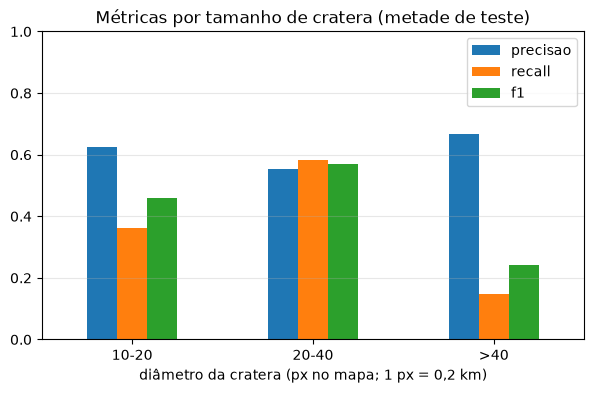

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
f = faixas.set_index("faixa")[["precisao", "recall", "f1"]]
f.plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_xlabel("diâmetro da cratera (px no mapa; 1 px = 0,2 km)")
ax.set_title("Métricas por tamanho de cratera (metade de teste)")
ax.grid(axis="y", alpha=0.3)
fig.savefig(config.PASTA_RESULTADOS / "deteccao_por_faixa.png", dpi=110, bbox_inches="tight")
plt.show()

## Limitações observadas

- O catálogo de Robbins foi feito à mão, por especialistas, sobre várias imagens. Ele inclui crateras **degradadas** (bordas suaves, quase sem sombra) que um limiar local não enxerga, e isso puxa o recall para baixo.
- Parte dos "falsos positivos" são crateras reais menores que 2 km ou ausentes do catálogo. A métrica trata o catálogo como verdade absoluta.
- As crateras grandes (> 40 px) têm interior complexo (picos centrais, terraços) e geram várias manchas de sombra. O pareamento simples acerta menos nelas.